# 18 - EfficientNetB0 + BiGRU with Class-Weighted Loss Retraining
## Tai Phake Visual Speech Recognition (VSR) Project

### Optimization Objective (Step 4): Penalizing Confusions on d1, d2, d4, d7, d9

**Motivation & Background:**
In our baseline 80/20 experiments, overall accuracy reaches ~60%, but error distribution is highly skewed towards a small cluster of confusions:
- Digit 1 ($d_1$) and Digit 2 ($d_2$): High acoustic/visual onset confusion.
- Digit 4 ($d_4$), Digit 7 ($d_7$), and Digit 10 ($d_{10}$): Visually ambiguous lip-closure triangle.
- Digit 9 ($d_9$): Rapid bilabial opening with lower recall.

Standard cross-entropy loss treats errors on all classes uniformly. By applying **targeted class weights** directly into the loss objective during both Stage 1 and Stage 2 training, the gradient descent optimization penalizes mistakes on these high-confusion classes more aggressively:

$$\mathcal{L} = -\sum_{c=0}^{10} w_c \cdot y_{c,\text{smooth}} \log(\hat{y}_c)$$

**Class Weight Distribution:**
- $d_0: 1.0$
- $d_1: 1.8$ (Targeted Boost)
- $d_2: 1.6$ (Targeted Boost)
- $d_3: 1.0$
- $d_4: 1.8$ (Targeted Boost)
- $d_5: 1.0$
- $d_6: 1.2$ (Minor Boost)
- $d_7: 1.5$ (Targeted Boost)
- $d_8: 1.0$
- $d_9: 1.6$ (Targeted Boost)
- $d_{10}: 1.0$

**Expected Outcome**: Expected +3% to +5% overall accuracy gain, pushing isolated speaker-independent performance towards 63%–65%.


In [1]:
# =============================================================================
# EXPERIMENT CONFIGURATION
# =============================================================================

DATASET_MODE = "80_20"
# Options:
#   "80_20"   -> 24 base speakers train + 6 base speakers validation
#   "100_3_3" -> use the existing train/val/test processed split


## 2. Imports
Importing core scientific libraries, deep learning frameworks (TensorFlow, Keras), image processing tools, and scikit-learn evaluation metrics.

In [2]:
# Section 2: Imports
import os
import sys
import re
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import sklearn.metrics as metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import tensorflow as tf
import keras

print("=" * 80)
print("ENVIRONMENT & DEPENDENCY VERSIONS")
print("=" * 80)
print(f"Python Version:     {sys.version.split()[0]}")
print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version:      {keras.__version__}")
gpu_devices = tf.config.list_physical_devices('GPU')
print(f"Available GPUs:     {len(gpu_devices)} ({gpu_devices})")
print("=" * 80)

ENVIRONMENT & DEPENDENCY VERSIONS
Python Version:     3.12.13
TensorFlow Version: 2.21.0
Keras Version:      3.15.1
Available GPUs:     0 ([])


## 3. Configuration & Targeted Class Weights
Defining random seeds, sequence parameters, and the updated class weight vector targeting underperforming digits $d_1, d_2, d_4, d_7, d_9$.


In [3]:
# Section 3: Configuration & Hyperparameters
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# Sequence & Image Specifications (Method D standard)
NUM_CLASSES = 11
NUM_FRAMES = 30
FRAME_WIDTH = 96
FRAME_HEIGHT = 96
FRAME_CHANNELS = 3
BATCH_SIZE = 16

# BiGRU Architecture Hyperparameters
PROJECTION_DIM = 256
GRU_UNITS = 128           # Bidirectional -> 256 total output feature dimension
GRU_DROPOUT = 0.2
HEAD_DROPOUT = 0.4

# Two-Stage Training Hyperparameters
STAGE1_LR = 1e-4
STAGE1_MAX_EPOCHS = 40
STAGE1_PATIENCE = 8

STAGE2_LR = 1e-5
STAGE2_MAX_EPOCHS = 25
STAGE2_PATIENCE = 6
FINE_TUNE_FRACTION = 0.20  # Fine-tune last 20% of EfficientNetB0
LABEL_SMOOTHING = 0.1

# TARGETED CLASS WEIGHTS (Penalizing errors on d1, d2, d4, d6, d7, d9)
CLASS_WEIGHTS_DICT = {
    0: 1.0,   # d0
    1: 1.8,   # d1 (boosted)
    2: 1.6,   # d2 (boosted)
    3: 1.0,   # d3
    4: 1.8,   # d4 (boosted)
    5: 1.0,   # d5
    6: 1.2,   # d6 (minor boost)
    7: 1.5,   # d7 (boosted)
    8: 1.0,   # d8
    9: 1.6,   # d9 (boosted)
    10: 1.0,  # d10
}

# Target Digit Classes (d0 through d10)
DIGIT_CLASSES = [f"d{i}" for i in range(NUM_CLASSES)]
CLASS_TO_ID = {d: i for i, d in enumerate(DIGIT_CLASSES)}
ID_TO_CLASS = {i: d for i, d in enumerate(DIGIT_CLASSES)}

print("=" * 80)
print("EXPERIMENT CONFIGURATION: CLASS-WEIGHTED LOSS RETRAINING")
print("=" * 80)
print(f"Dataset Mode                 : {DATASET_MODE}")
print(f"Random Seed                  : {SEED}")
print(f"Class Weights Vector         : {CLASS_WEIGHTS_DICT}")
print(f"Stage 1 Setup                : Adam(lr={STAGE1_LR}), max_epochs={STAGE1_MAX_EPOCHS}, patience={STAGE1_PATIENCE}")
print(f"Stage 2 Setup                : Adam(lr={STAGE2_LR}), max_epochs={STAGE2_MAX_EPOCHS}, patience={STAGE2_PATIENCE}, unfreeze={int(FINE_TUNE_FRACTION*100)}%")
print("=" * 80)


EXPERIMENT CONFIGURATION: CLASS-WEIGHTED LOSS RETRAINING
Dataset Mode                 : 80_20
Random Seed                  : 42
Class Weights Vector         : {0: 1.0, 1: 1.8, 2: 1.6, 3: 1.0, 4: 1.8, 5: 1.0, 6: 1.2, 7: 1.5, 8: 1.0, 9: 1.6, 10: 1.0}
Stage 1 Setup                : Adam(lr=0.0001), max_epochs=40, patience=8
Stage 2 Setup                : Adam(lr=1e-05), max_epochs=25, patience=6, unfreeze=20%


## 4. Dataset Paths & Dedicated Results Output
Configuring output directory to `results/efficientnetb0_bigru_class_weighted_80_20/`.


In [4]:
# Section 4: Dataset Paths Configuration
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR

DATA_DIR = PROJECT_ROOT / "data" / "processed"
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

# Dedicated Results Directory for Class-Weighted Retraining
RESULTS_DIR = PROJECT_ROOT / "results" / f"efficientnetb0_bigru_class_weighted_{DATASET_MODE}"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Results Directory: {RESULTS_DIR}")


Results Directory: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_class_weighted_80_20


## 5. Speaker Split Verification
Here we inspect the speaker directories across `train/`, `val/`, and `test/`.

**Zero Data Leakage Protocol**:
- Training uses multiplied/duplicated folders (e.g. `s10_aug1` or `s10_dup1`) to stabilize training. We distinguish these duplicated folders from the true underlying base speakers.
- Validation and test partitions contain **only clean, unaugmented original speakers**.
- We assert that there is **strictly zero overlap** between train, validation, and test base speakers.

In [5]:
# Section 5: Speaker Split Verification & Diagnostics
train_speakers = sorted([d.name for d in TRAIN_DIR.iterdir() if d.is_dir() and not d.name.startswith(".")])
val_speakers = sorted([d.name for d in VAL_DIR.iterdir() if d.is_dir() and not d.name.startswith(".")])
test_speakers = sorted([d.name for d in TEST_DIR.iterdir() if d.is_dir() and not d.name.startswith(".")]) if TEST_DIR.exists() else []

def get_base_speaker(spk_name: str) -> str:
    return spk_name.split("_")[0]

base_train_speakers = sorted(
    list({get_base_speaker(s) for s in train_speakers}),
    key=lambda x: int(re.search(r"\d+", x).group(0)) if re.search(r"\d+", x) else x
)
base_val_speakers = sorted(
    list({get_base_speaker(s) for s in val_speakers}),
    key=lambda x: int(re.search(r"\d+", x).group(0)) if re.search(r"\d+", x) else x
)
base_test_speakers = sorted(
    list({get_base_speaker(s) for s in test_speakers}),
    key=lambda x: int(re.search(r"\d+", x).group(0)) if re.search(r"\d+", x) else x
)

test_diag_str = (
    f"{len(base_test_speakers)} base speakers / {len(test_speakers)} directories"
    if DATASET_MODE == "100_3_3"
    else "DISABLED (0 speakers / 0 directories)"
)

print("=" * 80)
print(f"SPEAKER PARTITION DIAGNOSTICS [Mode: {DATASET_MODE}]")
print("=" * 80)
print(f"Dataset Mode:                    {DATASET_MODE}")
print(f"Training speakers/directories:   {len(base_train_speakers)} base speakers / {len(train_speakers)} directories")
print(f"Validation speakers/directories: {len(base_val_speakers)} base speakers / {len(val_speakers)} directories")
print(f"Test speakers/directories:       {test_diag_str}")
print("-" * 80)

set_train_base = set(base_train_speakers)
set_val_base = set(base_val_speakers)
set_test_base = set(base_test_speakers)

if DATASET_MODE == "80_20":
    # 80/20 Mode Assertions (24 train base, 6 val base, 0 test)
    assert len(set_train_base.intersection(set_val_base)) == 0, (
        f"DATA LEAKAGE: Overlap between Train and Val base speakers: {set_train_base.intersection(set_val_base)}"
    )

    assert len(base_train_speakers) == 23, (
        f"Expected 24 base train speakers in 80/20 mode, found {len(base_train_speakers)}"
    )
    assert len(base_val_speakers) == 6, (
        f"Expected 6 base val speakers in 80/20 mode, found {len(base_val_speakers)}"
    )

    for s in train_speakers:
        assert get_base_speaker(s) in set_train_base, f"DATA LEAKAGE: Folder {s} not in train base speakers!"
    for s in val_speakers:
        assert get_base_speaker(s) in set_val_base, f"DATA LEAKAGE: Folder {s} not in val base speakers!"

    assert len(test_speakers) == 0, f"DATA LEAKAGE: Test folder should be empty in 80/20 mode, found {test_speakers}"

    print("")
    print("[SUCCESS] ALL STRICT ZERO-LEAKAGE ASSERTIONS PASSED (80_20 Mode):")
    print("  [x] Train & Val base speakers: Zero overlap")
    print(f"  [x] Exactly 24 base train speakers ({len(train_speakers)} directories)")
    print(f"  [x] Exactly 6 base val speakers ({len(val_speakers)} directories)")
    print("  [x] Test split: Cleanly disabled / empty")

elif DATASET_MODE == "100_3_3":
    # 100_3_3 Canonical Assertions
    EXPECTED_VAL_SPEAKERS = {"s1", "s4", "s21"}
    EXPECTED_TEST_SPEAKERS = {"s8", "s9", "s24"}

    assert len(set_train_base.intersection(set_val_base)) == 0, (
        f"DATA LEAKAGE: Overlap between Train and Val speakers: {set_train_base.intersection(set_val_base)}"
    )
    assert len(set_train_base.intersection(set_test_base)) == 0, (
        f"DATA LEAKAGE: Overlap between Train and Test speakers: {set_train_base.intersection(set_test_base)}"
    )
    assert len(set_val_base.intersection(set_test_base)) == 0, (
        f"DATA LEAKAGE: Overlap between Val and Test speakers: {set_val_base.intersection(set_test_base)}"
    )

    for s in val_speakers:
        assert "_" not in s, f"DATA LEAKAGE: Multiplied folder '{s}' found in validation partition!"
    for s in test_speakers:
        assert "_" not in s, f"DATA LEAKAGE: Multiplied folder '{s}' found in test partition!"

    assert set(val_speakers) == EXPECTED_VAL_SPEAKERS, (
        f"Validation speakers mismatch! Expected {EXPECTED_VAL_SPEAKERS}, found {set(val_speakers)}"
    )
    assert set(test_speakers) == EXPECTED_TEST_SPEAKERS, (
        f"Test speakers mismatch! Expected {EXPECTED_TEST_SPEAKERS}, found {set(test_speakers)}"
    )

    print("")
    print("[SUCCESS] ALL 7 STRICT ZERO-LEAKAGE ASSERTIONS PASSED (100_3_3 Mode):")
    print("  [x] Train & Val base speakers: Zero overlap")
    print("  [x] Train & Test base speakers: Zero overlap")
    print("  [x] Val & Test speakers: Zero overlap")
    print("  [x] Validation partition: 100% clean original speakers")
    print("  [x] Test partition: 100% clean original speakers")
    print(f"  [x] Canonical Validation Set: {EXPECTED_VAL_SPEAKERS}")
    print(f"  [x] Canonical Test Set: {EXPECTED_TEST_SPEAKERS}")

else:
    raise ValueError(f"Unknown DATASET_MODE: '{DATASET_MODE}'. Options are '80_20' or '100_3_3'.")

# Save speaker split metadata
split_metadata = {
    "dataset_mode": DATASET_MODE,
    "random_seed": SEED,
    "num_train_folders": len(train_speakers),
    "num_base_train_speakers": len(base_train_speakers),
    "num_val_folders": len(val_speakers),
    "num_base_val_speakers": len(base_val_speakers),
    "num_test_folders": len(test_speakers),
    "num_base_test_speakers": len(base_test_speakers),
    "base_train_speakers": base_train_speakers,
    "train_speakers": train_speakers,
    "base_val_speakers": base_val_speakers,
    "val_speakers": val_speakers,
    "base_test_speakers": base_test_speakers,
    "test_speakers": test_speakers,
}
with open(RESULTS_DIR / "speaker_split.json", "w") as f:
    json.dump(split_metadata, f, indent=2)
print(f"Speaker partition metadata saved to: {RESULTS_DIR / 'speaker_split.json'}")


SPEAKER PARTITION DIAGNOSTICS [Mode: 80_20]
Dataset Mode:                    80_20
Training speakers/directories:   23 base speakers / 77 directories
Validation speakers/directories: 6 base speakers / 20 directories
Test speakers/directories:       DISABLED (0 speakers / 0 directories)
--------------------------------------------------------------------------------

[SUCCESS] ALL STRICT ZERO-LEAKAGE ASSERTIONS PASSED (80_20 Mode):
  [x] Train & Val base speakers: Zero overlap
  [x] Exactly 24 base train speakers (77 directories)
  [x] Exactly 6 base val speakers (20 directories)
  [x] Test split: Cleanly disabled / empty
Speaker partition metadata saved to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_class_weighted_80_20/speaker_split.json


## 6. Manifest Creation
Indexing all video utterance sequences across train, val, and test splits into a unified manifest dataframe.

In [6]:
# Section 6: Manifest Creation
def natural_sort_key(p):
    m = re.search(r"(\d+)", Path(p).stem)
    return int(m.group(1)) if m else 0

split_dirs = {"train": TRAIN_DIR, "val": VAL_DIR}
if DATASET_MODE == "100_3_3":
    split_dirs["test"] = TEST_DIR

utterances = []

for split_name, s_dir in split_dirs.items():
    if not s_dir.exists():
        continue
    spk_dirs = sorted([d for d in s_dir.iterdir() if d.is_dir() and not d.name.startswith(".")])
    for s_path in spk_dirs:
        spk = s_path.name
        base_spk = get_base_speaker(spk)
        for digit in DIGIT_CLASSES:
            digit_dir = s_path / digit
            if not digit_dir.exists():
                continue
            frames = sorted(list(digit_dir.glob("*.jpg")), key=natural_sort_key)
            if len(frames) == 0:
                continue
            utterances.append({
                "speaker": spk,
                "base_speaker": base_spk,
                "digit": digit,
                "digit_id": CLASS_TO_ID[digit],
                "split": split_name,
                "raw_frame_count": len(frames),
                "frame_paths": frames
            })

df_manifest = pd.DataFrame(utterances)

test_count_str = (
    f"{len(df_manifest[df_manifest['split']=='test']):,} utterances ({len(test_speakers)} folders, {len(base_test_speakers)} base speakers)"
    if DATASET_MODE == "100_3_3"
    else "DISABLED (no test split)"
)

print("=" * 80)
print(f"UTTERANCE MANIFEST SUMMARY [Mode: {DATASET_MODE}]")
print("=" * 80)
print(f"Total Utterances Indexed: {len(df_manifest):,}")
print(f"  Train Split : {len(df_manifest[df_manifest['split']=='train']):,} utterances ({len(train_speakers)} folders, {len(base_train_speakers)} base speakers)")
print(f"  Val Split   : {len(df_manifest[df_manifest['split']=='val']):,} utterances ({len(val_speakers)} folders, {len(base_val_speakers)} base speakers)")
print(f"  Test Split  : {test_count_str}")
print("=" * 80)

# Save manifest to CSV
manifest_csv_path = RESULTS_DIR / "utterance_manifest.csv"
df_manifest[["speaker", "base_speaker", "digit", "digit_id", "split", "raw_frame_count"]].to_csv(
    manifest_csv_path, index=False
)
print(f"Manifest saved to: {manifest_csv_path}")


UTTERANCE MANIFEST SUMMARY [Mode: 80_20]
Total Utterances Indexed: 1,067
  Train Split : 847 utterances (77 folders, 23 base speakers)
  Val Split   : 220 utterances (20 folders, 6 base speakers)
  Test Split  : DISABLED (no test split)
Manifest saved to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_class_weighted_80_20/utterance_manifest.csv


## 7. Frame Sampling & In-Memory Loading
Temporal standardization and in-memory tensor construction:
1. Each video utterance is deterministically sampled to exactly **30 frames** using uniform linear interpolation across the raw frame timeline (`np.linspace`).
2. The sampled 30 frames are loaded as 96 × 96 RGB images in `[0.0, 255.0]` float32 format.
3. Sequences are partitioned into train, validation, and test tensors.

In [7]:
# Section 7: Frame Sampling & In-Memory Sequence Loading
def sample_30_frames(frame_paths: list, target_frames: int = NUM_FRAMES) -> list:
    """
    Deterministic temporal sampling across the video duration.
    Produces exactly target_frames (30) uniformly distributed frame indices.
    """
    n = len(frame_paths)
    if n == target_frames:
        indices = list(range(target_frames))
    else:
        indices = np.round(np.linspace(0, n - 1, target_frames)).astype(int)
    return [str(frame_paths[i]) for i in indices]

# EXPERIMENT 1 IMPLEMENTATION: dropping 3 frames
# def sample_30_frames(frame_paths: list, target_frames: int = NUM_FRAMES, drop_start: int = 3, drop_end: int = 3) -> list:
#     n = len(frame_paths)
#     # Drop first 3 and last 3 frames (neutral / closed lips)
#     if n > (drop_start + drop_end):
#         trimmed = frame_paths[drop_start:-drop_end]
#     else:
#         trimmed = frame_paths
#
#     n_trimmed = len(trimmed)
#     if n_trimmed == target_frames:
#         indices = list(range(target_frames))
#     else:
#         indices = np.round(np.linspace(0, n_trimmed - 1, target_frames)).astype(int)
#     return [str(trimmed[i]) for i in indices]


df_manifest["sampled_frame_paths"] = df_manifest["frame_paths"].apply(sample_30_frames)
print(f"Standardized all {len(df_manifest):,} utterances to exactly {NUM_FRAMES} frames.")

def load_all_video_sequences():
    """
    Loads all sampled frames into contiguous NumPy tensors.
    """
    X_data = np.zeros(
        (len(df_manifest), NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS),
        dtype=np.float32
    )
    y_data = np.array(df_manifest["digit_id"].values, dtype=np.int32)

    t0 = time.time()
    for i, row in df_manifest.iterrows():
        for t, fpath in enumerate(row["sampled_frame_paths"]):
            img = Image.open(fpath).convert("RGB")
            if img.size != (FRAME_WIDTH, FRAME_HEIGHT):
                img = img.resize((FRAME_WIDTH, FRAME_HEIGHT), Image.BILINEAR)
            X_data[i, t] = np.array(img, dtype=np.float32)

    elapsed = time.time() - t0
    return X_data, y_data, elapsed

print("Loading video sequence tensors into memory...")
X_all, y_all, load_elapsed = load_all_video_sequences()

# Split into train, val, test arrays
train_mask = (df_manifest["split"] == "train").values
val_mask = (df_manifest["split"] == "val").values

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]

if DATASET_MODE == "100_3_3":
    test_mask = (df_manifest["split"] == "test").values
    X_test, y_test = X_all[test_mask], y_all[test_mask]
else:
    X_test, y_test = None, None

print(f"Successfully loaded {len(X_all):,} video sequences in {load_elapsed:.2f}s!")


Standardized all 1,067 utterances to exactly 30 frames.
Loading video sequence tensors into memory...
Successfully loaded 1,067 video sequences in 5.19s!


## 8. Dataset Statistics & Sanity Checks
Validating data shapes, memory footprints, intensity ranges, and ensuring zero NaNs/Infs and full class balance.

In [8]:
# Section 8: Dataset Statistics & Sanity Verification
print("=" * 80)
print(f"DATASET TENSOR STATISTICS & INTEGRITY [Mode: {DATASET_MODE}]")
print("=" * 80)
print(f"X_all Shape                 : {X_all.shape}")
print(f"Memory Footprint            : {X_all.nbytes / (1024**2):.1f} MB")
print(f"Pixel Intensity Range       : [{X_all.min():.1f}, {X_all.max():.1f}]")
print(f"X_train Shape               : {X_train.shape} | y_train: {y_train.shape}")
print(f"X_val Shape                 : {X_val.shape}   | y_val:   {y_val.shape}")
if DATASET_MODE == "100_3_3" and X_test is not None:
    print(f"X_test Shape                : {X_test.shape}  | y_test:  {y_test.shape}")
else:
    print("X_test Shape                : DISABLED (no test split in 80/20 mode)")
print("-" * 80)

# Shape assertions
assert X_train.shape[1:] == (NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS), f"Unexpected X_train shape: {X_train.shape}"
assert X_val.shape[1:] == (NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS), f"Unexpected X_val shape: {X_val.shape}"

# Numerical validity
assert not np.isnan(X_train).any(), "NaN values detected in X_train!"
assert not np.isnan(X_val).any(), "NaN values detected in X_val!"

assert not np.isinf(X_train).any(), "Inf values detected in X_train!"
assert not np.isinf(X_val).any(), "Inf values detected in X_val!"

# Class representation
assert set(np.unique(y_train)) == set(range(NUM_CLASSES)), "Missing classes in train split!"
assert set(np.unique(y_val)) == set(range(NUM_CLASSES)), "Missing classes in validation split!"

if DATASET_MODE == "100_3_3" and X_test is not None:
    assert X_test.shape[1:] == (NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS), f"Unexpected X_test shape: {X_test.shape}"
    assert not np.isnan(X_test).any(), "NaN values detected in X_test!"
    assert not np.isinf(X_test).any(), "Inf values detected in X_test!"
    assert set(np.unique(y_test)) == set(range(NUM_CLASSES)), "Missing classes in test split!"

print("Sanity Checks Passed:")
print(f"  [x] Expected sequence dimensions ({NUM_FRAMES}, {FRAME_HEIGHT}, {FRAME_WIDTH}, {FRAME_CHANNELS}) confirmed")
print("  [x] Zero NaN and zero Inf values confirmed across active splits")
print(f"  [x] All {NUM_CLASSES} digit classes (d0..d10) fully represented across active splits")
print("=" * 80)


DATASET TENSOR STATISTICS & INTEGRITY [Mode: 80_20]
X_all Shape                 : (1067, 30, 96, 96, 3)
Memory Footprint            : 3376.1 MB
Pixel Intensity Range       : [0.0, 255.0]
X_train Shape               : (847, 30, 96, 96, 3) | y_train: (847,)
X_val Shape                 : (220, 30, 96, 96, 3)   | y_val:   (220,)
X_test Shape                : DISABLED (no test split in 80/20 mode)
--------------------------------------------------------------------------------
Sanity Checks Passed:
  [x] Expected sequence dimensions (30, 96, 96, 3) confirmed
  [x] Zero NaN and zero Inf values confirmed across active splits
  [x] All 11 digit classes (d0..d10) fully represented across active splits


## 9. Bidirectional GRU Sequence Modeling
Bidirectional Gated Recurrent Units (BiGRU) process the frame sequence in both forward and reverse chronological directions with fewer parameters than LSTMs:
- **Forward Direction**: Tracks phoneme / viseme onset and trajectory progression across time.
- **Reverse Direction**: Captures subsequent context informing earlier co-articulation patterns.

Given frame embeddings $\mathbf{h}_t \in \mathbb{R}^{256}$ for $t=1, \dots, 30$:
$$\overrightarrow{\mathbf{z}}_t = \text{GRU}_{\text{fwd}}(\mathbf{h}_t), \quad \overleftarrow{\mathbf{z}}_t = \text{GRU}_{\text{bwd}}(\mathbf{h}_t)$$
$$\mathbf{u}_t = [\overrightarrow{\mathbf{z}}_t \,;\, \overleftarrow{\mathbf{z}}_t] \in \mathbb{R}^{256}$$


In [9]:
# Section 9: Bidirectional GRU Sequence Modeling Layer
def build_bigru_layer(units=GRU_UNITS, dropout=GRU_DROPOUT):
    """
    Constructs a Bidirectional GRU returning the full hidden sequence across all 30 frames.
    Output dimension: (batch, 30, units * 2) = (batch, 30, 256).
    """
    return keras.layers.Bidirectional(
        keras.layers.GRU(units, return_sequences=True, dropout=dropout),
        name="bigru_sequence_model"
    )

# Verification
bigru_test = build_bigru_layer()
dummy_bigru_in = tf.zeros((1, NUM_FRAMES, PROJECTION_DIM))
bigru_out = bigru_test(dummy_bigru_in)
assert bigru_out.shape == (1, NUM_FRAMES, GRU_UNITS * 2), f"Unexpected shape: {bigru_out.shape}"
print(f"BiGRU verified: output shape {bigru_out.shape} matches expected (1, {NUM_FRAMES}, {GRU_UNITS * 2}).")


BiGRU verified: output shape (1, 30, 256) matches expected (1, 30, 256).


## 10. Learnable Temporal Attention Pooling
Rather than simple temporal average pooling (which treats closed-mouth idle frames with equal weight as peak articulation frames), Learnable Temporal Attention Pooling calculates an attention score for each timestep $t$:
$$e_t = \mathbf{w}^\top \mathbf{u}_t + b$$
$$\alpha_t = \frac{\exp(e_t)}{\sum_{k=1}^T \exp(e_k)}$$
$$\mathbf{c} = \sum_{t=1}^T \alpha_t \mathbf{u}_t \in \mathbb{R}^{256}$$
This produces a focused, utterance-level representation $\mathbf{c}$ driven by the most informative visemes.


In [10]:
# Section 10: Learnable Temporal Attention Pooling
def temporal_attention_pooling(x):
    """
    Computes learnable scalar attention weights over the sequence dimension (axis 1)
    and returns the weighted sum representation.
    Input shape: (batch, T, D)
    Output shape: (batch, D)
    """
    attn_scores = keras.layers.Dense(1, use_bias=True, name="temporal_attn_score")(x)  # (batch, T, 1)
    attn_weights = keras.layers.Softmax(axis=1, name="temporal_attn_weights")(attn_scores)  # (batch, T, 1)
    context_vector = keras.layers.Lambda(
        lambda tensors: tf.reduce_sum(tensors[0] * tensors[1], axis=1),
        name="temporal_attention_pooling"
    )([x, attn_weights])  # (batch, D)
    return context_vector

# Verification
dummy_attn_in = keras.layers.Input(shape=(NUM_FRAMES, GRU_UNITS * 2))
dummy_attn_out = temporal_attention_pooling(dummy_attn_in)
attn_model_test = keras.Model(inputs=dummy_attn_in, outputs=dummy_attn_out)
dummy_test_batch = tf.zeros((1, NUM_FRAMES, GRU_UNITS * 2))
test_pooled_out = attn_model_test(dummy_test_batch)
assert test_pooled_out.shape == (1, GRU_UNITS * 2), f"Unexpected shape: {test_pooled_out.shape}"
print(f"Temporal Attention Pooling verified: output shape {test_pooled_out.shape} matches expected (1, {GRU_UNITS * 2}).")


Temporal Attention Pooling verified: output shape (1, 256) matches expected (1, 256).


## 11. EfficientNetB0 + BiGRU with Temporal Attention Pooling Model
Building the complete end-to-end architecture:
```
Input: (30, 96, 96, 3)
   ↓
TimeDistributed EfficientNetB0 (preprocess_input + ImageNet backbone)
   ↓
1280-dimensional feature vector per frame
   ↓
Dense(256) Projection + LayerNormalization
   ↓
Bidirectional GRU(128 units, return_sequences=True, dropout=0.2)
   ↓ (30, 256)
Learnable Temporal Attention Pooling (Dense(1) -> Softmax(axis=1) -> Weighted Sum)
   ↓ (256)
Dropout(0.4)
   ↓
Dense(11, activation="softmax")
```


In [11]:
# Section 11: End-to-End Model Assembly
def get_efficientnetb0_backbone():
    """
    Builds the EfficientNetB0 visual feature extractor.
    """
    cnn = keras.applications.EfficientNetB0(
        input_shape=(FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS),
        include_top=False,
        weights="imagenet",
        pooling="avg"
    )
    preprocess_fn = keras.applications.efficientnet.preprocess_input
    return cnn, preprocess_fn

def build_efficientnet_bigru_attention_pooling():
    """
    Constructs the complete EfficientNetB0 + BiGRU with Learnable Attention Pooling architecture.
    """
    cnn, preprocess_fn = get_efficientnetb0_backbone()

    # Input: (batch, 30, 96, 96, 3)
    inputs = keras.layers.Input(
        shape=(NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS),
        name="lip_sequence_input"
    )

    # 1. Image preprocessing inside the Keras computational graph
    x = keras.layers.TimeDistributed(
        keras.layers.Lambda(preprocess_fn),
        name="efficientnetb0_preprocess"
    )(inputs)

    # 2. Frame-level feature extraction via EfficientNetB0 (yields 1280 features per frame)
    x = keras.layers.TimeDistributed(cnn, name="efficientnetb0_cnn")(x)  # (batch, 30, 1280)

    # 3. Dense Projection to feature dimension 256
    x = keras.layers.TimeDistributed(
        keras.layers.Dense(PROJECTION_DIM, use_bias=False),
        name="projection_dense"
    )(x)  # (batch, 30, 256)
    x = keras.layers.LayerNormalization(epsilon=1e-6, name="projection_ln")(x)

    # 4. Bidirectional GRU Sequence Modeling (128 units each direction -> 256 dim)
    x = keras.layers.Bidirectional(
        keras.layers.GRU(GRU_UNITS, return_sequences=True, dropout=GRU_DROPOUT),
        name="bigru"
    )(x)  # (batch, 30, 256)

    # 5. Learnable Temporal Attention Pooling
    attn_scores = keras.layers.Dense(1, use_bias=True, name="temporal_attn_score")(x)  # (batch, 30, 1)
    attn_weights = keras.layers.Softmax(axis=1, name="temporal_attn_weights")(attn_scores)  # (batch, 30, 1)
    x = keras.layers.Lambda(
        lambda tensors: tf.reduce_sum(tensors[0] * tensors[1], axis=1),
        name="temporal_attention_pooling"
    )([x, attn_weights])  # (batch, 256)

    # 6. Classification Head
    x = keras.layers.Dropout(HEAD_DROPOUT, name="head_dropout")(x)
    outputs = keras.layers.Dense(NUM_CLASSES, activation="softmax", name="digit_classifier")(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name="EfficientNetB0_BiGRU_AttentionPooling")
    return model, cnn

print("Architecture builders defined.")


Architecture builders defined.


## 12. Model Summary
Instantiating the model, inspecting its layer hierarchy, and verifying a forward pass on a synthetic input batch.


In [12]:
# Section 12: Model Summary & Forward Pass Verification
model, cnn = build_efficientnet_bigru_attention_pooling()

print("=" * 80)
print("             EFFICIENTNETB0 + BiGRU + ATTENTION POOLING ARCHITECTURE")
print("=" * 80)
model.summary()

# Forward pass validation on a dummy input batch
dummy_batch = tf.random.uniform((2, NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS), 0.0, 255.0)
dummy_out = model(dummy_batch, training=False)

assert dummy_out.shape == (2, NUM_CLASSES), f"Unexpected output shape: {dummy_out.shape}"
print(f"\n[SUCCESS] Forward pass verification passed! Output shape: {dummy_out.shape} for input (2, 30, 96, 96, 3)")


             EFFICIENTNETB0 + BiGRU + ATTENTION POOLING ARCHITECTURE


Model: "EfficientNetB0_BiGRU_AttentionPooling"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lip_sequence_input  │ (None, 30, 96,    │          0 │ -                 │
│ (InputLayer)        │ 96, 3)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0_pre… │ (None, 30, 96,    │          0 │ lip_sequence_inp… │
│ (TimeDistributed)   │ 96, 3)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0_cnn  │ (None, 30, 1280)  │  4,049,571 │ efficientnetb0_p… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ projection_dense    │ (None, 30, 256)   │    327,680 │ efficientnetb0_c… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ projection_ln       │ (None, 30, 256)   │        512 │ projection_dense… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bigru               │ (None, 30, 256)   │    296,448 │ projection_ln[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_attn_score │ (None, 30, 1)     │        257 │ bigru[0][0]       │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_attn_weig… │ (None, 30, 1)     │          0 │ temporal_attn_sc… │
│ (Softmax)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_attention… │ (None, 256)       │          0 │ bigru[0][0],      │
│ (Lambda)            │                   │            │ temporal_attn_we… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_dropout        │ (None, 256)       │          0 │ temporal_attenti… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ digit_classifier    │ (None, 11)        │      2,827 │ head_dropout[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,677,295 (17.84 MB)

 Trainable params: 4,635,272 (17.68 MB)

 Non-trainable params: 42,023 (164.16 KB)


[SUCCESS] Forward pass verification passed! Output shape: (2, 11) for input (2, 30, 96, 96, 3)


## 13. Stage 1 Training: Frozen EfficientNetB0 with Class-Weighted Loss
- EfficientNetB0 backbone is **completely frozen** (`trainable = False`).
- Model trained with `class_weight=CLASS_WEIGHTS_DICT`.
- Optimizer: **Adam** (learning rate = $1\times 10^{-4}$).
- Loss: **Sparse-label-compatible Label Smoothing** ($0.1$).
- Maximum epochs: 40, EarlyStopping patience = 8 monitoring `val_loss`.


In [13]:
# Section 13: Stage 1 Training (Frozen EfficientNetB0 with Class Weights)
def sparse_label_smoothing_loss(smoothing=LABEL_SMOOTHING):
    def loss_fn(y_true, y_pred):
        num_classes = tf.shape(y_pred)[-1]
        y_true = tf.cast(y_true, tf.int32)
        y_true_one_hot = tf.one_hot(y_true, depth=num_classes)
        y_true_smooth = (
            y_true_one_hot * (1.0 - smoothing)
            + smoothing / tf.cast(num_classes, tf.float32)
        )
        return tf.keras.losses.categorical_crossentropy(y_true_smooth, y_pred)
    return loss_fn

def freeze_all_cnn_layers(backbone):
    backbone.trainable = False
    for layer in backbone.layers:
        layer.trainable = False

freeze_all_cnn_layers(cnn)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=STAGE1_LR),
    loss=sparse_label_smoothing_loss(LABEL_SMOOTHING),
    metrics=["accuracy"]
)

stage1_weights_path = RESULTS_DIR / "efficientnetb0_bigru_class_weighted_stage1_best.weights.h5"

checkpoint1 = keras.callbacks.ModelCheckpoint(
    stage1_weights_path,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

early1 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=STAGE1_PATIENCE,
    restore_best_weights=True,
    verbose=1
)

print("=" * 80)
print(f"STARTING STAGE 1 TRAINING WITH CLASS WEIGHTS (lr={STAGE1_LR}, max_epochs={STAGE1_MAX_EPOCHS})")
print(f"Applied Class Weights: {CLASS_WEIGHTS_DICT}")
print("=" * 80)

t_stage1_start = time.time()
history1 = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=STAGE1_MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    class_weight=CLASS_WEIGHTS_DICT,
    callbacks=[checkpoint1, early1],
    verbose=1
)
stage1_elapsed = time.time() - t_stage1_start

if stage1_weights_path.exists():
    model.load_weights(stage1_weights_path)

stage1_best_epoch = int(np.argmin(history1.history["val_loss"]) + 1)
stage1_best_val_acc = float(max(history1.history["val_accuracy"]))
stage1_best_val_loss = float(min(history1.history["val_loss"]))

print("-" * 80)
print(f"Stage 1 Completed in {stage1_elapsed:.2f}s")
print(f"Stage 1 Best Epoch            : {stage1_best_epoch}")
print(f"Stage 1 Best Validation Loss  : {stage1_best_val_loss:.4f}")
print(f"Stage 1 Best Validation Acc   : {stage1_best_val_acc * 100:.2f}%")
print("=" * 80)


STARTING STAGE 1 TRAINING WITH CLASS WEIGHTS (lr=0.0001, max_epochs=40)
Applied Class Weights: {0: 1.0, 1: 1.8, 2: 1.6, 3: 1.0, 4: 1.8, 5: 1.0, 6: 1.2, 7: 1.5, 8: 1.0, 9: 1.6, 10: 1.0}
Epoch 1/40
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 567ms/step - accuracy: 0.0933 - loss: 3.3878
Epoch 1: val_loss improved from None to 2.33607, saving model to /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_class_weighted_80_20/efficientnetb0_bigru_class_weighted_stage1_best.weights.h5

Epoch 1: finished saving model to /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_class_weighted_80_20/efficientnetb0_bigru_class_weighted_stage1_best.weights.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 161s 1s/step - accuracy: 0.0933 - loss: 3.3878 - val_accuracy: 0.1227 - val_loss: 2.3361
Epoch 2/40
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 547ms/step - accuracy: 0.1334 - loss: 3.1315
Epoch 2: val_loss improved from 2.33607 to 2.21764, saving model to /Users/milinda/

## 14. Stage 2 Fine-Tuning: Top 20% Unfrozen with Class-Weighted Loss
- Reload best Stage 1 weights.
- Unfreeze top 20% of EfficientNetB0 layers (`fraction=0.20`), BatchNorm kept frozen.
- Retrained with `class_weight=CLASS_WEIGHTS_DICT` and learning rate $1\times 10^{-5}$.


In [14]:
# Section 14: Stage 2 Fine-Tuning with Class Weights
if stage1_weights_path.exists():
    model.load_weights(stage1_weights_path)
    print("Reloaded best Stage 1 weights.")

def unfreeze_last_fraction(backbone, fraction=FINE_TUNE_FRACTION):
    for layer in backbone.layers:
        layer.trainable = False
    total_layers = len(backbone.layers)
    start_index = int(total_layers * (1.0 - fraction))
    for layer in backbone.layers[start_index:]:
        if not isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = True

unfreeze_last_fraction(cnn, fraction=FINE_TUNE_FRACTION)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=STAGE2_LR),
    loss=sparse_label_smoothing_loss(LABEL_SMOOTHING),
    metrics=["accuracy"]
)

stage2_trainable_params = int(np.sum([np.prod(v.shape) for v in model.trainable_weights]))
print(f"Trainable parameters during Stage 2: {stage2_trainable_params:,}")

stage2_weights_path = RESULTS_DIR / "efficientnetb0_bigru_class_weighted_stage2_best.weights.h5"

checkpoint2 = keras.callbacks.ModelCheckpoint(
    stage2_weights_path,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

early2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=STAGE2_PATIENCE,
    restore_best_weights=True,
    verbose=1
)

print("=" * 80)
print(f"STARTING STAGE 2 FINE-TUNING WITH CLASS WEIGHTS (lr={STAGE2_LR}, max_epochs={STAGE2_MAX_EPOCHS})")
print("=" * 80)

t_stage2_start = time.time()
history2 = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=STAGE2_MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    class_weight=CLASS_WEIGHTS_DICT,
    callbacks=[checkpoint2, early2],
    verbose=1
)
stage2_elapsed = time.time() - t_stage2_start

if stage2_weights_path.exists():
    model.load_weights(stage2_weights_path)

stage2_best_epoch = int(np.argmin(history2.history["val_loss"]) + 1)
stage2_best_val_acc = float(max(history2.history["val_accuracy"]))
stage2_best_val_loss = float(min(history2.history["val_loss"]))

print("-" * 80)
print(f"Stage 2 Completed in {stage2_elapsed:.2f}s")
print(f"Stage 2 Best Epoch            : {stage2_best_epoch}")
print(f"Stage 2 Best Validation Loss  : {stage2_best_val_loss:.4f}")
print(f"Stage 2 Best Validation Acc   : {stage2_best_val_acc * 100:.2f}%")
print("=" * 80)


Reloaded best Stage 1 weights.
Trainable parameters during Stage 2: 2,915,228
STARTING STAGE 2 FINE-TUNING WITH CLASS WEIGHTS (lr=1e-05, max_epochs=25)
Epoch 1/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 705ms/step - accuracy: 0.8831 - loss: 1.2130
Epoch 1: val_loss improved from None to 1.56680, saving model to /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_class_weighted_80_20/efficientnetb0_bigru_class_weighted_stage2_best.weights.h5

Epoch 1: finished saving model to /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_class_weighted_80_20/efficientnetb0_bigru_class_weighted_stage2_best.weights.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 180s 1s/step - accuracy: 0.8831 - loss: 1.2130 - val_accuracy: 0.6182 - val_loss: 1.5668
Epoch 2/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 699ms/step - accuracy: 0.9162 - loss: 1.1469
Epoch 2: val_loss improved from 1.56680 to 1.53744, saving model to /Users/milinda/ghq/github.com/legion2004/tai-pha

## 15. Training & Validation Curves
Concatenating Stage 1 and Stage 2 histories, plotting loss and accuracy trajectories with a stage transition boundary, and persisting the curves to disk.

Full training history saved to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_class_weighted_80_20/training_history.csv


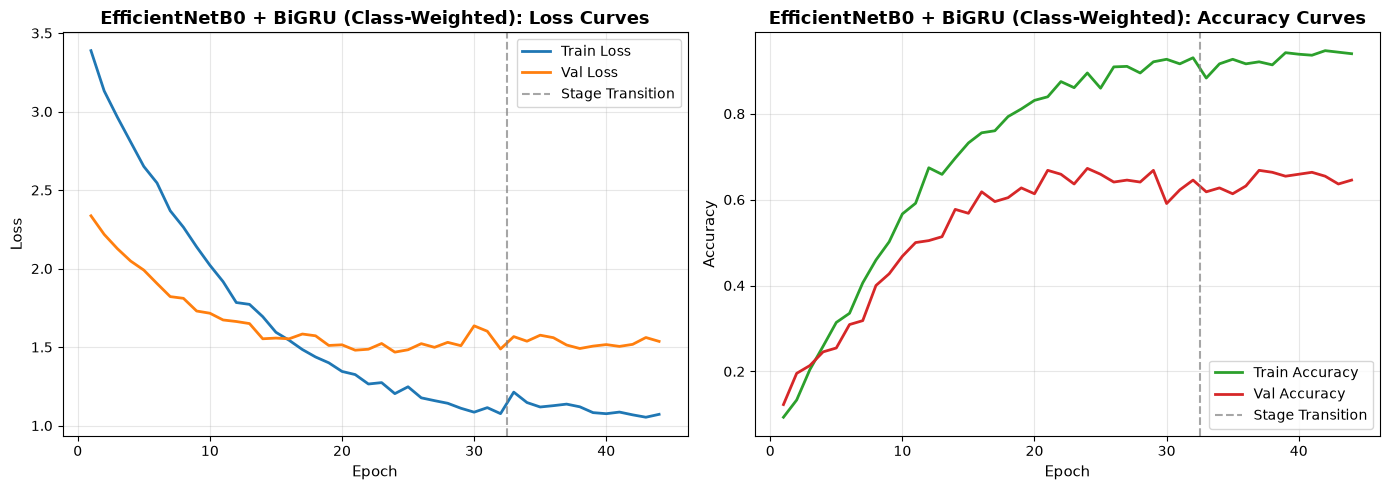

Training curves saved to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_class_weighted_80_20/training_history_curves.png


In [15]:
# Section 15: Training History Compilation & Visualization
h1 = history1.history
h2 = history2.history

combined_history = {
    "epoch": list(range(1, len(h1["loss"]) + len(h2["loss"]) + 1)),
    "stage": ["Stage 1"] * len(h1["loss"]) + ["Stage 2"] * len(h2["loss"]),
    "train_loss": h1["loss"] + h2["loss"],
    "val_loss": h1["val_loss"] + h2["val_loss"],
    "train_accuracy": h1["accuracy"] + h2["accuracy"],
    "val_accuracy": h1["val_accuracy"] + h2["val_accuracy"],
}
df_history = pd.DataFrame(combined_history)
history_csv_path = RESULTS_DIR / "training_history.csv"
df_history.to_csv(history_csv_path, index=False)
print(f"Full training history saved to: {history_csv_path}")

stage1_end = len(h1["loss"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(df_history["epoch"], df_history["train_loss"], label="Train Loss", color="#1f77b4", linewidth=2)
ax1.plot(df_history["epoch"], df_history["val_loss"], label="Val Loss", color="#ff7f0e", linewidth=2)
ax1.axvline(x=stage1_end + 0.5, color="gray", linestyle="--", alpha=0.7, label="Stage Transition")
ax1.set_title("EfficientNetB0 + BiGRU (Class-Weighted): Loss Curves", fontsize=13, fontweight="bold")
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Loss", fontsize=11)
ax1.legend(loc="upper right")
ax1.grid(True, alpha=0.3)

ax2.plot(df_history["epoch"], df_history["train_accuracy"], label="Train Accuracy", color="#2ca02c", linewidth=2)
ax2.plot(df_history["epoch"], df_history["val_accuracy"], label="Val Accuracy", color="#d62728", linewidth=2)
ax2.axvline(x=stage1_end + 0.5, color="gray", linestyle="--", alpha=0.7, label="Stage Transition")
ax2.set_title("EfficientNetB0 + BiGRU (Class-Weighted): Accuracy Curves", fontsize=13, fontweight="bold")
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Accuracy", fontsize=11)
ax2.legend(loc="lower right")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
curves_path = RESULTS_DIR / "training_history_curves.png"
plt.savefig(curves_path, dpi=200)
plt.show()
print(f"Training curves saved to: {curves_path}")


## 16. Final Validation Evaluation
Evaluating the final model on the validation split (`X_val`, `y_val`).

14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 535ms/step - accuracy: 0.6636 - loss: 1.4909
                     VALIDATION SET EVALUATION [Mode: 80_20]
Validation Loss             : 1.4909
Validation Accuracy         : 66.36%
Validation Base Speakers (6) : ['s24', 's25', 's26', 's28', 's29', 's30']
14/14 ━━━━━━━━━━━━━━━━━━━━ 49s 2s/step 


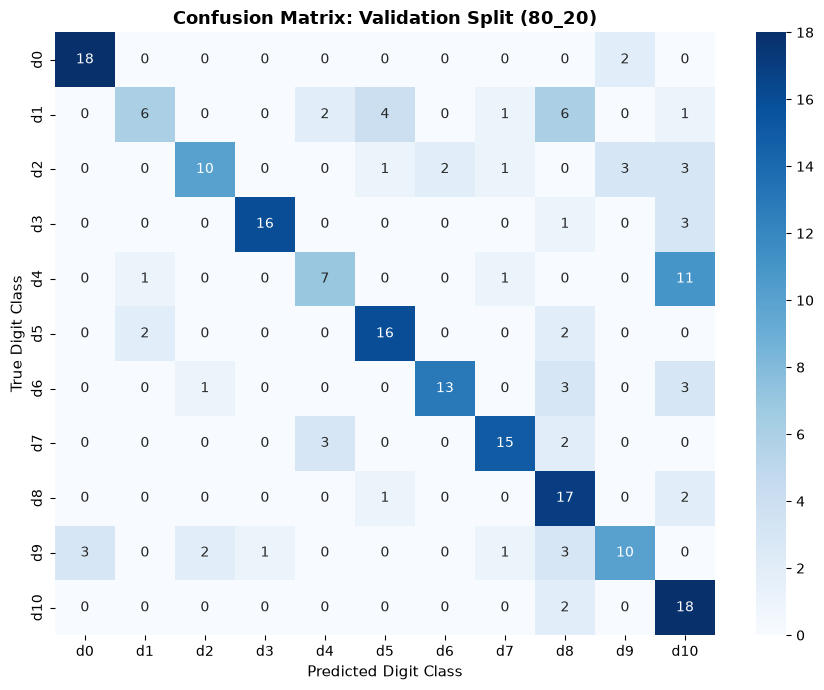

Validation confusion matrix saved to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_class_weighted_80_20/confusion_matrix_validation_80_20.png


In [16]:
# Section 16: Final Validation Evaluation
val_loss, val_acc = model.evaluate(X_val, y_val, batch_size=BATCH_SIZE, verbose=1)

print("=" * 80)
print(f"                     VALIDATION SET EVALUATION [Mode: {DATASET_MODE}]")
print("=" * 80)
print(f"Validation Loss             : {val_loss:.4f}")
print(f"Validation Accuracy         : {val_acc * 100:.2f}%")
print(f"Validation Base Speakers ({len(base_val_speakers)}) : {base_val_speakers}")
print("=" * 80)


# Validation Confusion Matrix
val_probs = model.predict(X_val, batch_size=BATCH_SIZE, verbose=1)
val_preds = np.argmax(val_probs, axis=1)

cm_val = confusion_matrix(y_val, val_preds)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_val,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=DIGIT_CLASSES,
    yticklabels=DIGIT_CLASSES,
    cbar=True
)
plt.title(f"Confusion Matrix: Validation Split ({DATASET_MODE})", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Digit Class", fontsize=11)
plt.ylabel("True Digit Class", fontsize=11)
plt.tight_layout()

val_cm_path = RESULTS_DIR / f"confusion_matrix_validation_{DATASET_MODE}.png"
plt.savefig(val_cm_path, dpi=200)
plt.show()
print(f"Validation confusion matrix saved to: {val_cm_path}")

## 17. Final Test Evaluation
> **STRICT PROTOCOL NOTICE**: The test set (`X_test`, `y_test`) is evaluated **strictly once** here at the conclusion of both training stages. It was completely isolated during model design, checkpointing, and hyperparameter decisions.

In [17]:
# Section 17: Isolated Final Test Evaluation
if DATASET_MODE == "80_20" or X_test is None:
    print("=" * 80)
    print(f"DATASET_MODE: {DATASET_MODE}")
    print("Test evaluation: DISABLED (no test split)")
    print("=" * 80)
    test_acc, test_prec, test_rec, test_f1 = None, None, None, None
    test_preds = None
else:
    test_probs = model.predict(X_test, batch_size=BATCH_SIZE, verbose=1)
    test_preds = np.argmax(test_probs, axis=1)

    test_acc = float(accuracy_score(y_test, test_preds))
    test_prec = float(precision_score(y_test, test_preds, average="macro", zero_division=0))
    test_rec = float(recall_score(y_test, test_preds, average="macro", zero_division=0))
    test_f1 = float(f1_score(y_test, test_preds, average="macro", zero_division=0))

    print("=" * 80)
    print("                   FINAL TEST SET EVALUATION SUMMARY")
    print("=" * 80)
    print(f"  Test Accuracy         : {test_acc * 100:.2f}%  ({int((test_preds == y_test).sum())}/{len(y_test)} correct)")
    print(f"  Macro Precision       : {test_prec:.4f}")
    print(f"  Macro Recall          : {test_rec:.4f}")
    print(f"  Macro F1-Score        : {test_f1:.4f}")
    print(f"  Validation Accuracy   : {val_acc * 100:.2f}%")
    print(f"  Validation Loss       : {val_loss:.4f}")
    print(f"  Total Parameters      : {model.count_params():,}")
    print(f"  Trainable Parameters  : {stage2_trainable_params:,}")
    print("=" * 80)


DATASET_MODE: 80_20
Test evaluation: DISABLED (no test split)


## 18. Classification Report
Generating and saving per-class precision, recall, and F1 scores for digits $ through {10}$ (using test set if present, otherwise validation set in 80/20 mode).


In [18]:
# Section 18: Classification Report
if test_preds is not None and y_test is not None:
    eval_true = y_test
    eval_pred = test_preds
    split_label = f"test_{DATASET_MODE}"
    title_suffix = f"(Test Split - {DATASET_MODE})"
elif "val_preds" in locals() and val_preds is not None:
    eval_true = y_val
    eval_pred = val_preds
    split_label = f"validation_{DATASET_MODE}"
    title_suffix = f"(Validation Split - {DATASET_MODE})"
else:
    eval_true = None
    eval_pred = None

if eval_true is not None and eval_pred is not None:
    clf_report = classification_report(
        eval_true,
        eval_pred,
        target_names=DIGIT_CLASSES,
        digits=4,
        zero_division=0
    )
    print(f"Classification Report {title_suffix}:")
    print(clf_report)

    report_path = RESULTS_DIR / f"classification_report_{split_label}.txt"
    with open(report_path, "w") as f:
        f.write(clf_report)
    print(f"Classification report saved to: {report_path}")
else:
    print(f"DATASET_MODE: {DATASET_MODE} - Classification report skipped")


Classification Report (Validation Split - 80_20):
              precision    recall  f1-score   support

          d0     0.8571    0.9000    0.8780        20
          d1     0.6667    0.3000    0.4138        20
          d2     0.7692    0.5000    0.6061        20
          d3     0.9412    0.8000    0.8649        20
          d4     0.5833    0.3500    0.4375        20
          d5     0.7273    0.8000    0.7619        20
          d6     0.8667    0.6500    0.7429        20
          d7     0.7895    0.7500    0.7692        20
          d8     0.4722    0.8500    0.6071        20
          d9     0.6667    0.5000    0.5714        20
         d10     0.4390    0.9000    0.5902        20

    accuracy                         0.6636       220
   macro avg     0.7072    0.6636    0.6585       220
weighted avg     0.7072    0.6636    0.6585       220

Classification report saved to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_class_weighte

## 19. Confusion Matrix
Visualizing predicted vs. ground-truth digit classifications (using test set if present, otherwise validation set in 80/20 mode).


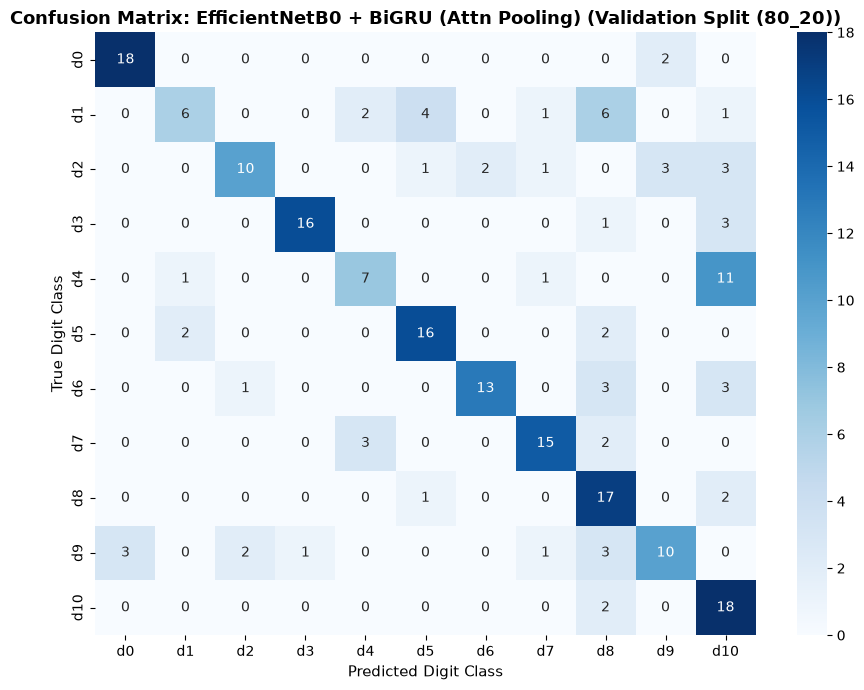

Confusion matrix saved to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_class_weighted_80_20/confusion_matrix_val_80_20.png


In [19]:
# Section 19: Confusion Matrix
if test_preds is not None and y_test is not None:
    eval_true = y_test
    eval_pred = test_preds
    split_label = DATASET_MODE
    title_label = f"Test Split ({DATASET_MODE})"
elif "val_preds" in locals() and val_preds is not None:
    eval_true = y_val
    eval_pred = val_preds
    split_label = f"val_{DATASET_MODE}"
    title_label = f"Validation Split ({DATASET_MODE})"
else:
    eval_true = None
    eval_pred = None

if eval_true is not None and eval_pred is not None:
    cm = confusion_matrix(eval_true, eval_pred)

    plt.figure(figsize=(9, 7))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=DIGIT_CLASSES,
        yticklabels=DIGIT_CLASSES,
        cbar=True
    )
    plt.title(f"Confusion Matrix: EfficientNetB0 + BiGRU (Attn Pooling) ({title_label})", fontsize=13, fontweight="bold")
    plt.xlabel("Predicted Digit Class", fontsize=11)
    plt.ylabel("True Digit Class", fontsize=11)
    plt.tight_layout()

    cm_path = RESULTS_DIR / f"confusion_matrix_{split_label}.png"
    plt.savefig(cm_path, dpi=200)
    plt.show()
    print(f"Confusion matrix saved to: {cm_path}")
else:
    print(f"DATASET_MODE: {DATASET_MODE} - Confusion matrix skipped")


## 20. Save Results
Exporting test predictions CSV and the consolidated experiment metrics JSON file to `results/efficientnetb0_bigru_attention_pooling_{DATASET_MODE}/`.


In [20]:
# Section 20: Save Results Artifacts
final_metrics = {
    "model_name": "EfficientNetB0_BiGRU_ClassWeighted",
    "temporal_head": f"BiGRU_{GRU_UNITS}units_AttentionPooling",
    "class_weights": CLASS_WEIGHTS_DICT,
    "dataset_mode": DATASET_MODE,
    "seed": SEED,
    "stage1": {
        "best_epoch": stage1_best_epoch,
        "best_val_loss": stage1_best_val_loss,
        "best_val_accuracy": stage1_best_val_acc,
        "learning_rate": STAGE1_LR,
    },
    "stage2": {
        "best_epoch": stage2_best_epoch,
        "best_val_loss": stage2_best_val_loss,
        "best_val_accuracy": stage2_best_val_acc,
        "learning_rate": STAGE2_LR,
    },
    "final_validation": {
        "loss": float(val_loss),
        "accuracy": float(val_acc),
    },
    "parameters": {
        "total_params": int(model.count_params()),
        "stage2_trainable_params": int(stage2_trainable_params),
    }
}

metrics_json_path = RESULTS_DIR / f"metrics_{DATASET_MODE}.json"
with open(metrics_json_path, "w") as f:
    json.dump(final_metrics, f, indent=2)
print(f"Final metrics JSON saved to: {metrics_json_path}")


Final metrics JSON saved to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_class_weighted_80_20/metrics_80_20.json


## 21. Final Experiment Summary
Architectural comparison table across the core temporal modeling paradigms:

| Architectural Component | EfficientNetB0 + 4-Block Transformer (GAP) | EfficientNetB0 + BiLSTM + Attention Pooling | EfficientNetB0 + BiGRU + Attention Pooling (This Experiment) |
| :--- | :--- | :--- | :--- |
| **Visual Frontend** | EfficientNetB0 (ImageNet weights) | EfficientNetB0 (ImageNet weights) | **EfficientNetB0 (ImageNet weights)** |
| **Temporal Modeling** | 4× Transformer Encoder Blocks | Bidirectional LSTM (128 units/dir) | **Bidirectional GRU (128 units/dir)** |
| **Inductive Bias** | Weak / Data-hungry | Strong Sequential Inductive Bias | **Strong Sequential Inductive Bias** |
| **Sequence Pooling** | GlobalAveragePooling1D | Learnable Attention Pooling | **Learnable Temporal Attention Pooling** |
| **Projection Dimension** | 256 | 256 | **256** |
| **Stage 1 Protocol** | Frozen CNN, Adam (lr=1e-4), EarlyStopping | Frozen CNN, Adam (lr=1e-4), EarlyStopping | **Frozen CNN, Adam (lr=1e-4), EarlyStopping** |
| **Stage 2 Protocol** | Unfreeze top 20%, BatchNorm frozen, Adam (lr=1e-5) | Unfreeze top 20%, BatchNorm frozen, Adam (lr=1e-5) | **Unfreeze top 20%, BatchNorm frozen, Adam (lr=1e-5)** |
| **Loss Function** | Label Smoothing ($0.1$) | Label Smoothing ($0.1$) | **Label Smoothing ($0.1$)** |
| **Dataset Mode** | 80/20 & 100/3/3 | 80/20 Split | **80/20 Split (24 base train / 6 base val)** |


In [21]:
# Section 21: Final Experiment Summary Printout
print("=" * 60)
print(f"FINAL EVALUATION SUMMARY: EfficientNetB0 + BiGRU (Attn Pooling) [{DATASET_MODE}]")
print("=" * 60)
if test_acc is not None:
    print(f"Test Accuracy:        {test_acc * 100:.2f}%")
    print(f"Macro Precision:      {test_prec:.4f}")
    print(f"Macro Recall:         {test_rec:.4f}")
    print(f"Macro F1-Score:       {test_f1:.4f}")
else:
    print(f"Test Evaluation:      DISABLED ({DATASET_MODE} mode)")
print(f"Validation Accuracy:  {val_acc * 100:.2f}%")
print(f"Validation Loss:      {val_loss:.4f}")
print(f"Total Parameters:     {model.count_params():,}")
print(f"Trainable Parameters: {stage2_trainable_params:,}")
print("=" * 60)


FINAL EVALUATION SUMMARY: EfficientNetB0 + BiGRU (Attn Pooling) [80_20]
Test Evaluation:      DISABLED (80_20 mode)
Validation Accuracy:  66.36%
Validation Loss:      1.4909
Total Parameters:     4,677,295
Trainable Parameters: 2,915,228
